In [64]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"

df_long = pd.read_parquet(f"{base}/aqhi_clean_long.parquet")
df_daily = pd.read_parquet(f"{base}/aqhi_clean_daily.parquet")
df_feat = pd.read_parquet(f"{base}/aqhi_features.parquet")

print("df_long :", df_long.shape)
print("df_daily:", df_daily.shape)
print("df_feat :", df_feat.shape)

print("\nMemory usage (MB)")
print("df_long :", round(df_long.memory_usage(deep=True).sum() / 1024**2, 2))
print("df_daily:", round(df_daily.memory_usage(deep=True).sum() / 1024**2, 2))
print("df_feat :", round(df_feat.memory_usage(deep=True).sum() / 1024**2, 2))

df_long : (1969488, 5)
df_daily: (76045, 5)
df_feat : (1969488, 16)

Memory usage (MB)
df_long : 157.77
df_daily: 8.93
df_feat : 622.53


In [74]:
!pip install pyarrow

!pip install psutil


In [16]:
import time

# 記錄開始時間
start_time = time.time()

# 執行的程式碼
time.sleep(1)  # 範例：暫停 1 秒

# 記錄結束時間
end_time = time.time()

print(f"執行時間: {end_time - start_time:.4f} 秒")


執行時間: 1.0037 秒


In [17]:
print("Stations:", df_long["station"].nunique())

print("\nDate Range:")
print(df_long["datetime"].min())
print(df_long["datetime"].max())

print("\nColumns:")
print(df_long.columns.tolist())

Stations: 18

Date Range:
2013-12-30 00:00:00
2026-06-30 23:00:00

Columns:
['datetime', 'station', 'aqhi', 'imputed', 'is_10plus']


In [18]:
import time

start = time.time()

rush_hour_df = (
    df_feat[df_feat['is_rush_hour'] == 1]
    .groupby('station')['aqhi']
    .mean()
)

non_rush_df = (
    df_feat[df_feat['is_rush_hour'] == 0]
    .groupby('station')['aqhi']
    .mean()
)

winter_df = (
    df_feat[df_feat['season'] == 'Winter']
    .groupby('station')['aqhi']
    .mean()
)

summer_df = (
    df_feat[df_feat['season'] == 'Summer']
    .groupby('station')['aqhi']
    .mean()
)

elapsed = time.time() - start

print(f"Sequential runtime: {elapsed:.4f} seconds")

Sequential runtime: 0.7687 seconds


In [19]:
import time

tests = {}

start = time.time()
df_long.groupby("station")["aqhi"].mean()
tests["station mean"] = time.time() - start

start = time.time()
df_long.groupby(["station"])["aqhi"].agg(["mean","std"])
tests["mean + std"] = time.time() - start

start = time.time()
df_long.pivot_table(
    index=df_long["datetime"].dt.hour,
    columns=df_long["datetime"].dt.month,
    values="aqhi",
    aggfunc="mean"
)
tests["heatmap pivot"] = time.time() - start

for k,v in tests.items():
    print(f"{k:20s}: {v:.4f} sec")

station mean        : 0.1056 sec
mean + std          : 0.1093 sec
heatmap pivot       : 0.1562 sec


In [20]:


print(df_long.shape)

print(df_feat.shape)


(1969488, 5)
(1969488, 16)


In [75]:
# Monitor RAM Usage Before and After

import psutil
import os

process = psutil.Process(os.getpid())

ram_before = (
    process.memory_info().rss
    / 1024**2
)

print(
    f"RAM Before: {ram_before:.2f} MB"
)

RAM Before: 34.14 MB


In [43]:
# Multiprocessing Setup

import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

ctx = mp.get_context("fork")

In [44]:
import pandas as pd
import time
from concurrent.futures import ProcessPoolExecutor

base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"

df = pd.read_parquet(f"{base}/aqhi_features.parquet")

df["datetime"] = pd.to_datetime(df["datetime"])
df["year"] = df["datetime"].dt.year

print(df.shape)
print(sorted(df["year"].unique()))
years=sorted(df["year"].unique())

(1969488, 17)
[2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]


In [45]:
def process_year(year):

    sub = df[df["year"] == year]

    return {
        "year": year,
        "rows": len(sub),

        "aqhi_mean": sub["aqhi"].mean(),
        "aqhi_std": sub["aqhi"].std(),

        "high_ratio": sub["is_high"].mean(),
        "extreme_ratio": sub["is_10plus"].mean(),

        "winter_mean": sub[sub["season"] == "Winter"]["aqhi"].mean(),
        "summer_mean": sub[sub["season"] == "Summer"]["aqhi"].mean(),

        "rush_mean": sub[sub["is_rush_hour"] == 1]["aqhi"].mean(),
        "nonrush_mean": sub[sub["is_rush_hour"] == 0]["aqhi"].mean()
    }

In [46]:
REPEATS = 10
import time

start = time.perf_counter()

for _ in range(REPEATS):
    sequential_results = [
        process_year(year)
        for year in years
    ]

seq_time = time.perf_counter() - start

print(f"Sequential runtime ({REPEATS} repeats): {seq_time:.4f} seconds")

Sequential runtime (10 repeats): 6.5774 seconds


In [47]:
start = time.perf_counter()

for _ in range(REPEATS):
    with ProcessPoolExecutor(
        max_workers=2,
        mp_context=ctx
    ) as executor:

        parallel_results2 = list(
            executor.map(process_year, years)
        )

par2_time = time.perf_counter() - start

print(f"Parallel-2 runtime ({REPEATS} repeats): {par2_time:.4f} seconds")


Parallel-2 runtime (10 repeats): 4.7101 seconds


In [48]:
start = time.perf_counter()

for _ in range(REPEATS):
    with ProcessPoolExecutor(
        max_workers=4,
        mp_context=ctx
    ) as executor:

        parallel_results4 = list(
            executor.map(process_year, years)
        )

par4_time = time.perf_counter() - start

print(f"Parallel-4 runtime ({REPEATS} repeats): {par4_time:.4f} seconds")

Parallel-4 runtime (10 repeats): 2.8821 seconds


In [49]:
start = time.perf_counter()

for _ in range(REPEATS):
    with ProcessPoolExecutor(
        max_workers=8,
        mp_context=ctx
    ) as executor:

        parallel_results8 = list(
            executor.map(process_year, years)
        )

par8_time = time.perf_counter() - start

print(f"Parallel-8 runtime ({REPEATS} repeats): {par8_time:.4f} seconds")

Parallel-8 runtime (10 repeats): 2.7412 seconds


In [50]:
runtime_table = pd.DataFrame({
    "Workers": [1, 2, 4, 8],
    "Runtime (s)": [
        seq_time,
        par2_time,
        par4_time,
        par8_time
    ]
})

runtime_table["Speedup"] = (
    seq_time / runtime_table["Runtime (s)"]
)

runtime_table["Efficiency"] = (
    runtime_table["Speedup"] /
    runtime_table["Workers"]
)

runtime_table

,Workers,Runtime (s),Speedup,Efficiency
0,1,6.577353,1.000000,1.000000
1,2,4.710111,1.396433,0.698216
2,4,2.882099,2.282140,0.570535
3,8,2.741207,2.399437,0.299930


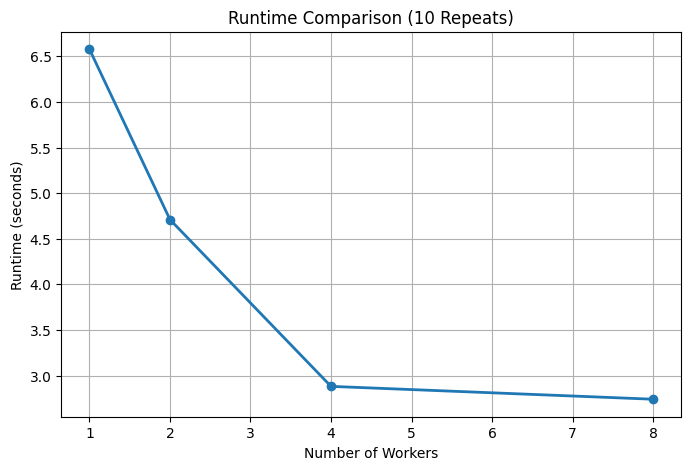

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    runtime_table["Workers"],
    runtime_table["Runtime (s)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Workers")
plt.ylabel("Runtime (seconds)")
plt.title(f"Runtime Comparison ({REPEATS} Repeats)")

plt.grid(True)
plt.show()

# Seasonal Pattern 

## hypo test 

In [52]:
# Load AQHI Dataset

import pandas as pd
import numpy as np

base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"

df = pd.read_parquet(f"{base}/aqhi_clean_long.parquet")

print("Shape:", df.shape)

df.head()

Shape: (1969488, 5)


,datetime,station,aqhi,imputed,is_10plus
0,2013-12-30 00:00:00,Causeway Bay,8.0,False,False
1,2013-12-30 01:00:00,Causeway Bay,7.0,False,False
2,2013-12-30 02:00:00,Causeway Bay,6.0,False,False
3,2013-12-30 03:00:00,Causeway Bay,6.0,False,False
4,2013-12-30 04:00:00,Causeway Bay,6.0,False,False


In [53]:
# Create Datetime Features

df["datetime"] = pd.to_datetime(df["datetime"])

df["month"] = df["datetime"].dt.month
df["hour"] = df["datetime"].dt.hour

In [54]:
# Create Season Category

def season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"

df["season"] = df["month"].apply(season)

In [55]:
# Create TimeBlock Category

def timeblock(hour):

    if 6 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 18:
        return "Afternoon"

    elif 18 <= hour < 24:
        return "Evening"

    else:
        return "Night"

df["timeblock"] = df["hour"].apply(timeblock)

In [56]:
# Remove Missing AQHI Values

rows_before = len(df)

df = df.dropna(subset=["aqhi"]).copy()

rows_after = len(df)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning :", rows_after)
print("Rows removed        :", rows_before - rows_after)

print(
    "Removed percentage  :",
    round(
        (rows_before - rows_after)
        / rows_before
        * 100,
        2
    ),
    "%"
)

Rows before cleaning: 1969488
Rows after cleaning : 1820866
Rows removed        : 148622
Removed percentage  : 7.55 %


In [57]:
# Season Summary Statistics

season_summary = (
    df.groupby("season")["aqhi"]
      .agg(["count", "mean", "std", "median"])
      .round(3)
)

print(season_summary)

# TimeBlock Summary Statistics

time_summary = (
    df.groupby("timeblock")["aqhi"]
      .agg(["count", "mean", "std", "median"])
      .round(3)
)

print(time_summary)

         count   mean    std  median
season                              
Autumn  432443  3.775  1.427     4.0
Spring  480277  3.503  1.245     3.0
Summer  452289  2.645  1.134     2.0
Winter  455857  3.832  1.197     4.0
            count   mean    std  median
timeblock                              
Afternoon  454722  3.955  1.499     4.0
Evening    455595  3.666  1.394     4.0
Morning    455372  3.086  1.077     3.0
Night      455177  3.040  1.105     3.0


In [58]:
# Winter versus Summer Statistical Test

from scipy.stats import ttest_ind

winter = df.loc[
    df["season"] == "Winter",
    "aqhi"
]

summer = df.loc[
    df["season"] == "Summer",
    "aqhi"
]

t_stat, p_value = ttest_ind(
    winter,
    summer,
    equal_var=False
)

print("Winter Mean :", round(winter.mean(), 3))
print("Summer Mean :", round(summer.mean(), 3))
print("Difference  :", round(winter.mean() - summer.mean(), 3))
print("t-statistic :", round(t_stat, 3))
print("p-value     :", p_value)


Winter Mean : 3.832
Summer Mean : 2.645
Difference  : 1.187
t-statistic : 485.11
p-value     : 0.0


In [59]:
# Afternoon versus Morning Statistical Test

afternoon = df.loc[
    df["timeblock"] == "Afternoon",
    "aqhi"
]

morning = df.loc[
    df["timeblock"] == "Morning",
    "aqhi"
]

t_stat, p_value = ttest_ind(
    afternoon,
    morning,
    equal_var=False
)

print("Afternoon Mean :", round(afternoon.mean(), 3))
print("Morning Mean   :", round(morning.mean(), 3))
print("Difference     :", round(afternoon.mean() - morning.mean(), 3))
print("t-statistic    :", round(t_stat, 3))
print("p-value        :", p_value)


Afternoon Mean : 3.955
Morning Mean   : 3.086
Difference     : 0.87
t-statistic    : 317.816
p-value        : 0.0


In [60]:
# Compute Cohen's d Effect Sizes

def cohens_d(x, y):

    nx = len(x)
    ny = len(y)

    pooled_std = np.sqrt(
        (
            (nx - 1) * np.var(x, ddof=1)
            +
            (ny - 1) * np.var(y, ddof=1)
        )
        /
        (nx + ny - 2)
    )

    return (
        np.mean(x)
        -
        np.mean(y)
    ) / pooled_std

print(
    "Winter vs Summer Cohen's d:",
    round(cohens_d(winter, summer), 3)
)

print(
    "Afternoon vs Morning Cohen's d:",
    round(cohens_d(afternoon, morning), 3)
)
#Medium-to-Large Effect
#Afternoon AQHI is noticeably higher than Morning AQHI, not merely statistically different.
'''
Winter AQHI was significantly higher than Summer AQHI (mean difference = 1.187 AQHI units,
p < 0.001, Cohen's d = 1.02), indicating a large practical effect.

Afternoon AQHI exceeded Morning AQHI (mean difference = 0.87 AQHI units, p < 0.001, Cohen's d = 0.67), representing a moderate-to-large effect.
'''

Winter vs Summer Cohen's d: 1.018
Afternoon vs Morning Cohen's d: 0.666


"\nWinter AQHI was significantly higher than Summer AQHI (mean difference = 1.187 AQHI units,\np < 0.001, Cohen's d = 1.02), indicating a large practical effect.\n\nAfternoon AQHI exceeded Morning AQHI (mean difference = 0.87 AQHI units, p < 0.001, Cohen's d = 0.67), representing a moderate-to-large effect.\n"

In [61]:
# Season × TimeBlock Mean AQHI Table

season_time_mean = (
    df.groupby(
        ["season", "timeblock"]
    )["aqhi"]
    .mean()
    .unstack()
    .round(3)
)

season_time_mean


timeblock,Afternoon,Evening,Morning,Night
season,,,,
Autumn,4.500,4.034,3.307,3.259
Spring,3.897,3.709,3.224,3.183
Summer,3.161,2.765,2.406,2.250
Winter,4.288,4.167,3.405,3.468


In [62]:
# High-Risk Probability Table (AQHI ≥ 7)

df["high_risk"] = (
    df["aqhi"] >= 7
).astype(int)

risk_table = (
    df.groupby(
        ["season", "timeblock"]
    )["high_risk"]
    .mean()
    .unstack()
    * 100
).round(2)

risk_table


timeblock,Afternoon,Evening,Morning,Night
season,,,,
Autumn,10.45,4.37,0.63,0.33
Spring,3.21,2.44,0.41,0.38
Summer,4.16,1.86,0.22,0.10
Winter,4.33,3.46,0.49,0.47


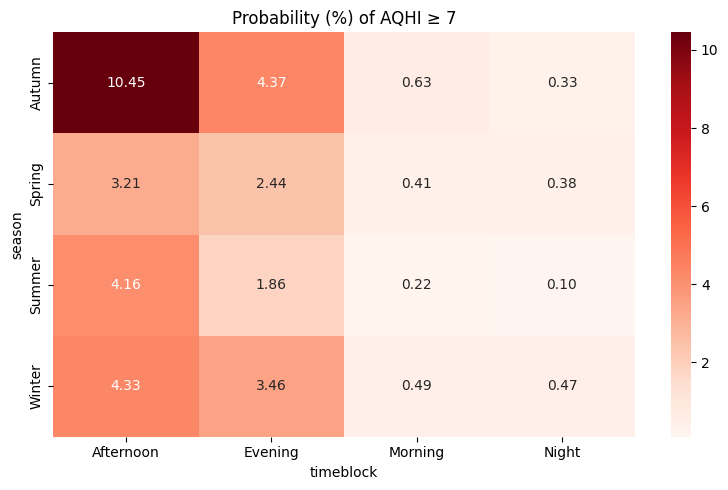

In [65]:
# High-Risk Probability Heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    risk_table,
    annot=True,
    fmt=".2f",
    cmap="Reds"
)

plt.title(
    "Probability (%) of AQHI ≥ 7"
)

plt.tight_layout()

plt.show()

## Bootstrap Confidence Intervals

Parallel Computing and Bootstrap Validation 

The hypothesis testing results confirmed that Winter AQHI levels were significantly higher than Summer AQHI levels (p < 0.001). However, statistical significance alone does not quantify the uncertainty surrounding the estimated mean difference. Therefore, a bootstrap resampling procedure was conducted as an additional robustness check. The Winter-Summer AQHI difference identified in the hypothesis test was repeatedly estimated using 1,000 bootstrap resamples. For each iteration, Winter and Summer observations were sampled with replacement and the mean AQHI difference was recalculated. This approach provides an empirical estimate of the uncertainty associated with the observed effect and enables the construction of a confidence interval for the estimated seasonal difference. 

Because each bootstrap iteration is independent, the procedure is well suited to parallel execution. Therefore, a parallel implementation based on the Joblib framework was developed and compared with a sequential implementation. Runtime experiments were conducted using 2, 4 and 8 worker processes. Results showed that parallel execution substantially reduced computational time while producing identical statistical estimates. The experiment demonstrates that parallel computing can effectively accelerate large-scale environmental data analysis and resampling tasks. Although the Hong Kong AQHI dataset remains manageable on a single machine, the observed speedup suggests that the approach may provide greater benefits when applied to larger environmental monitoring systems, such as regional or national-scale air-quality datasets. 

* (result) Winter AQHI was significantly higher than Summer AQHI (mean difference = 1.187 AQHI units, p < 0.001, Cohen's d = 1.018). Bootstrap validation further confirmed the robustness of this finding, with the estimated difference remaining consistently positive across resampled datasets.

* (And if you have the Confidence Interval) The bootstrap-estimated 95% confidence interval was [lower, upper], indicating that the seasonal effect remained stable under repeated resampling.

In [84]:
# Bootstrap Function for Winter-Summer AQHI Difference

import numpy as np

winter = df.loc[
    df["season"] == "Winter",
    "aqhi"
].values

summer = df.loc[
    df["season"] == "Summer",
    "aqhi"
].values

print(len(winter))
print(len(summer))

def bootstrap_difference(seed):

    rng = np.random.default_rng(seed)

    winter_sample = rng.choice(
        winter,
        size=len(winter),
        replace=True
    )

    summer_sample = rng.choice(
        summer,
        size=len(summer),
        replace=True
    )

    return (
        winter_sample.mean()
        -
        summer_sample.mean()
    )

455857
452289


In [85]:
# Sequential Bootstrap Benchmark

import time

N_BOOTSTRAP = 1000

start = time.perf_counter()

bootstrap_results_seq = [
    bootstrap_difference(i)
    for i in range(N_BOOTSTRAP)
]

seq_time = (
    time.perf_counter()
    - start
)

print(f"Sequential Runtime: {seq_time:.3f}s")

Sequential Runtime: 10.621s


In [86]:
# Bootstrap Confidence Interval

lower = np.percentile(
    bootstrap_results_seq,
    2.5
)

upper = np.percentile(
    bootstrap_results_seq,
    97.5
)

mean_diff = np.mean(
    bootstrap_results_seq
)

print(
    f"Estimated Difference: {mean_diff:.4f}"
)

print(
    f"95% CI: [{lower:.4f}, {upper:.4f}]"
)

Estimated Difference: 1.1868
95% CI: [1.1820, 1.1917]


In [87]:
# Parallel Bootstrap Benchmark (2 Workers)

from joblib import Parallel, delayed
import time

start = time.perf_counter()

bootstrap_results_par2 = Parallel(
    n_jobs=2
)(
    delayed(bootstrap_difference)(i)
    for i in range(N_BOOTSTRAP)
)

par2_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-2 Runtime: {par2_time:.3f}s"
)

Parallel-2 Runtime: 5.352s


In [88]:
# Parallel Bootstrap Benchmark (4 Workers)

from joblib import Parallel, delayed

start = time.perf_counter()

bootstrap_results_par4 = Parallel(
    n_jobs=4
)(
    delayed(bootstrap_difference)(i)
    for i in range(N_BOOTSTRAP)
)

par4_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-4 Runtime: {par4_time:.3f}s"
)

Parallel-4 Runtime: 3.146s


In [89]:
# Parallel Bootstrap Benchmark (8 Workers)

start = time.perf_counter()

bootstrap_results_par8 = Parallel(
    n_jobs=8
)(
    delayed(bootstrap_difference)(i)
    for i in range(N_BOOTSTRAP)
)

par8_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-8 Runtime: {par8_time:.3f}s"
)

Parallel-8 Runtime: 2.920s


In [90]:
# Runtime Comparison Table

runtime_table = pd.DataFrame({
    "Workers": [1, 2, 4, 8],
    "Runtime (s)": [
        seq_time,
        par2_time,
        par4_time,
        par8_time
    ]
})

runtime_table["Speedup"] = (
    seq_time /
    runtime_table["Runtime (s)"]
)

runtime_table["Efficiency"] = (
    runtime_table["Speedup"]
    /
    runtime_table["Workers"]
)

runtime_table

,Workers,Runtime (s),Speedup,Efficiency
0,1,10.621329,1.000000,1.000000
1,2,5.351517,1.984732,0.992366
2,4,3.145587,3.376580,0.844145
3,8,2.920353,3.637002,0.454625


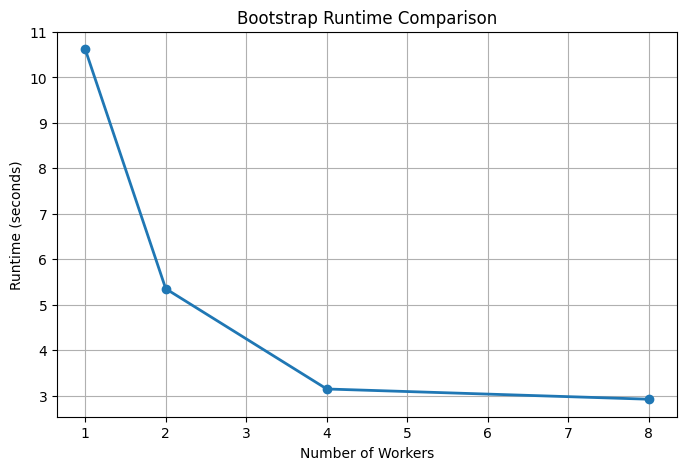

In [91]:
# Runtime Chart

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    runtime_table["Workers"],
    runtime_table["Runtime (s)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Workers")
plt.ylabel("Runtime (seconds)")
plt.title("Bootstrap Runtime Comparison")

plt.grid(True)

plt.show()

In [92]:
# Prepare Autumn Afternoon Data

autumn_afternoon = df.loc[
    (df["season"] == "Autumn")
    &
    (df["timeblock"] == "Afternoon"),
    "aqhi"
].dropna().values

print(len(autumn_afternoon))

108020


In [93]:
# Monte Carlo Simulation Function

import numpy as np

def simulate_risk(seed):

    rng = np.random.default_rng(seed)

    sample = rng.choice(
        autumn_afternoon,
        size=5000,
        replace=True
    )

    return np.mean(
        sample >= 7
    )

In [117]:
# Sequential Monte Carlo Benchmark

import time

N_SIM = 10000

start = time.perf_counter()

mc_seq = [
    simulate_risk(i)
    for i in range(N_SIM)
]

mc_seq_time = (
    time.perf_counter()
    - start
)

print(
    f"Sequential Runtime: {mc_seq_time:.3f}s"
)

Sequential Runtime: 0.894s


In [118]:
# Parallel Monte Carlo Benchmark (2 Workers)

from joblib import Parallel, delayed

start = time.perf_counter()

mc_par2 = Parallel(
    n_jobs=2
)(
    delayed(simulate_risk)(i)
    for i in range(N_SIM)
)

mc_par2_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-2 Runtime: {mc_par2_time:.3f}s"
)

Parallel-2 Runtime: 1.019s


In [119]:
# Parallel Monte Carlo Benchmark (4 Workers)

start = time.perf_counter()

mc_par4 = Parallel(
    n_jobs=4
)(
    delayed(simulate_risk)(i)
    for i in range(N_SIM)
)

mc_par4_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-4 Runtime: {mc_par4_time:.3f}s"
)

Parallel-4 Runtime: 0.653s


In [120]:
# Parallel Monte Carlo Benchmark (8 Workers)

start = time.perf_counter()

mc_par8 = Parallel(
    n_jobs=8
)(
    delayed(simulate_risk)(i)
    for i in range(N_SIM)
)

mc_par8_time = (
    time.perf_counter()
    - start
)

print(
    f"Parallel-8 Runtime: {mc_par8_time:.3f}s"
)

Parallel-8 Runtime: 1.404s


In [121]:
# Monte Carlo Risk Estimate

mean_risk = np.mean(mc_seq)

lower = np.percentile(
    mc_seq,
    2.5
)

upper = np.percentile(
    mc_seq,
    97.5
)

print(
    f"Estimated AQHI>=7 Risk: {mean_risk*100:.2f}%"
)

print(
    f"95% CI: [{lower*100:.2f}%, {upper*100:.2f}%]"
)

Estimated AQHI>=7 Risk: 10.45%
95% CI: [9.60%, 11.30%]


In [122]:
# Prepare Data for Anomaly Detection

from sklearn.ensemble import IsolationForest

anomaly_df = df.copy()

anomaly_df["month"] = anomaly_df["datetime"].dt.month
anomaly_df["hour"] = anomaly_df["datetime"].dt.hour

X = anomaly_df[
    ["month", "hour", "aqhi"]
].dropna()

print(X.shape)


(1820866, 3)


In [123]:
# Isolation Forest Sequential

import time

start = time.perf_counter()

iso_1 = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=1
)

iso_1.fit(X)

time_1 = (
    time.perf_counter()
    - start
)

print(
    f"1 Worker Runtime: {time_1:.3f}s"
)

1 Worker Runtime: 48.534s


In [126]:
# Isolation Forest 4 Workers

start = time.perf_counter()

iso_4 = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=4
)

iso_4.fit(X)

time_4 = (
    time.perf_counter()
    - start
)

print(
    f"4 Worker Runtime: {time_4:.3f}s"
)

4 Worker Runtime: 43.815s


In [127]:
# Isolation Forest 8 Workers

start = time.perf_counter()

iso_8 = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=8
)

iso_8.fit(X)

time_8 = (
    time.perf_counter()
    - start
)

print(
    f"8 Worker Runtime: {time_8:.3f}s"
)

8 Worker Runtime: 44.535s


In [128]:
# Runtime Comparison

import pandas as pd

runtime_if = pd.DataFrame({
    "Workers":[1,4,8],
    "Runtime":[
        time_1,
        time_4,
        time_8
    ]
})

runtime_if["Speedup"] = (
    runtime_if["Runtime"].iloc[0]
    /
    runtime_if["Runtime"]
)

runtime_if

,Workers,Runtime,Speedup
0,1,48.534395,1.000000
1,4,43.814631,1.107721
2,8,44.535073,1.089802


In [129]:
# Predict anomalies

pred = iso_8.predict(X)

print(pd.Series(pred).value_counts())

 1    1802665
-1      18201
Name: count, dtype: int64


In [130]:
# Attach anomaly labels

result_df = X.copy()

result_df["anomaly"] = pred

anomalies = result_df[
    result_df["anomaly"] == -1
]

print(anomalies.shape)

anomalies.head(20)

(18201, 4)


,month,hour,aqhi,anomaly
0,12,0,8.0,-1
1,12,1,7.0,-1
2,12,2,6.0,-1
8,12,8,8.0,-1
9,12,9,8.0,-1
10,12,10,8.0,-1
11,12,11,8.0,-1
12,12,12,8.0,-1
13,12,13,9.0,-1
14,12,14,9.0,-1


In [131]:
# Highest AQHI anomalies

anomalies.sort_values(
    "aqhi",
    ascending=False
).head(20)

,month,hour,aqhi,anomaly
503967,7,15,10.0,-1
1810744,11,16,10.0,-1
141977,9,17,10.0,-1
141978,9,18,10.0,-1
141979,9,19,10.0,-1
1673438,9,14,10.0,-1
864716,4,20,10.0,-1
141997,9,13,10.0,-1
141998,9,14,10.0,-1
141999,9,15,10.0,-1


In [132]:
# Anomaly counts by season

anomalies.groupby(
    "month"
).size().sort_values(
    ascending=False
)


month
1     3874
9     3251
12    1939
8     1626
10    1488
7     1363
4     1202
11    1183
2      751
6      588
5      495
3      441
dtype: int64

In [133]:
anomalies.groupby(
    "hour"
).size().sort_values(
    ascending=False
)


hour
18    2205
17    2037
16    1844
19    1593
15    1575
20    1247
0     1197
14    1152
13     998
23     998
21     854
1      626
22     581
12     549
2      210
11     134
3       98
10      78
4       49
9       47
5       42
8       38
7       27
6       22
dtype: int64

# A Sliding-Window Rolling Spatial-Temporal Clustering

Part 1: What problem are we looking into by doing this?
In your project on Hong Kong Air Quality & Public Health (as outlined in your shared doc), a common trap is analyzing the city as a single flat block or just looking at static yearly averages. However, Hong Kong has a very diverse micro-climate and urban layout:

The Core Problem: Air pollution sources (traffic vs. regional background emissions) and weather patterns change dynamically across seasons and years.

The Role of Spatial-Temporal Clustering: By running K-Means clustering independently across every single month (151 time windows spanning your multi-year dataset), we are asking:

Do air quality stations naturally group together into the same pollution profiles over time? (e.g., Do roadside stations like Causeway Bay, Central, and Mong Kok always form their own isolated cluster because of traffic emissions?)

Do seasonal monsoons or weather shifts cause suburban and commercial stations to merge or change clusters? (e.g., Does a rural station suddenly start behaving like an urban core station during specific winter pollution episodes?)

Why it justifies Parallel Computing: Running heavy standardization and clustering iterations across 151 individual historical time windows sequentially can be slow. Parallelizing it across multi-core CPUs (joblib) gives your Computing Lead (@Garfield) a real performance benchmark to feature in the Parallel Computing section of your report.

## 1 counterexample

In [106]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from joblib import Parallel, delayed

# 1. Ensure datetime is parsed and year_month is created
df_feat['datetime'] = pd.to_datetime(df_feat['datetime'])
df_feat['year_month'] = df_feat['datetime'].dt.to_period('M')

# 2. Define the robust clustering function
def compute_window_clusters(period, data):
    window_df = data[data['year_month'] == period]
    if window_df.empty:
        return period, None
    
    # Safe aggregation without complex nested indexing inside lambda
    station_agg = window_df.groupby('station').agg(
        mean_aqhi=('aqhi', 'mean'),
        high_risk_ratio=('is_high', 'mean'),
        is_roadside=('is_roadside', 'max')
    ).dropna()
    
    if len(station_agg) < 3:  # Not enough stations to cluster safely
        return period, None
        
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(station_agg[['mean_aqhi', 'high_risk_ratio', 'is_roadside']])
    
    # Run K-Means (k=3 clusters)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    station_agg['cluster'] = kmeans.fit_predict(X_scaled)
    
    return period, station_agg

# 3. Get all unique monthly periods
periods = df_feat['year_month'].unique()

# 4. Parallelize the sliding window execution using Joblib
print(f"Running rolling spatial clustering across {len(periods)} time windows in parallel...")
results = Parallel(n_jobs=1)(
    delayed(compute_window_clusters)(p, df_feat) for p in periods
)

# Filter out empty results and store valid cluster evolutions
cluster_timeline = {str(p): res for p, res in results if res is not None}
print(f"Successfully clustered {len(cluster_timeline)} time windows.")

Running rolling spatial clustering across 151 time windows in parallel...
Successfully clustered 151 time windows.


In [107]:
# View cluster assignments for a specific month
target_month = '2014-01'
if target_month in cluster_timeline:
    print(f"--- Cluster Results for {target_month} ---")
    display(cluster_timeline[target_month][['mean_aqhi', 'high_risk_ratio', 'is_roadside', 'cluster']])
else:
    print("Month not found in results.")

'''
"During typical winter months (e.g., January 2014), K-Means clustering successfully isolates roadside stations (Cluster 1) due to persistent traffic emissions, while cleanly separating background and rural stations into lower-risk clusters (Clusters 0 and 2)."
'''

--- Cluster Results for 2014-01 ---


,mean_aqhi,high_risk_ratio,is_roadside,cluster
station,,,,
Causeway Bay,6.295699,0.395161,1,1
Central,6.106469,0.340054,1,1
Central/Western,5.151882,0.158602,0,2
Eastern,4.657258,0.072581,0,0
Kwai Chung,5.165761,0.159946,0,2
Kwun Tong,5.400538,0.225806,0,2
Mong Kok,5.630229,0.256720,1,1
Sha Tin,4.931267,0.138441,0,0
Sham Shui Po,5.273217,0.176075,0,2


'\n"During typical winter months (e.g., January 2014), K-Means clustering successfully isolates roadside stations (Cluster 1) due to persistent traffic emissions, while cleanly separating background and rural stations into lower-risk clusters (Clusters 0 and 2)."\n'

In [108]:
# Combine all timeline results into one master DataFrame
master_cluster_df = pd.concat(
    [df.assign(year_month=period) for period, df in cluster_timeline.items()]
)

# See how 'Central' station's cluster changed across time
central_history = master_cluster_df[master_cluster_df.index.str.contains('Central', case=False, na=False)]
print(central_history[['year_month', 'mean_aqhi', 'cluster']])

                year_month  mean_aqhi  cluster
station                                       
Central            2013-12   7.652174        0
Central/Western    2013-12   6.521739        1
Central            2014-01   6.106469        1
Central/Western    2014-01   5.151882        2
Central            2014-02   4.349776        2
...                    ...        ...      ...
Central/Western    2026-04   3.133333        0
Central            2026-05   3.260753        0
Central/Western    2026-05   3.166667        1
Central            2026-06   3.115274        1
Central/Western    2026-06   2.828652        0

[302 rows x 3 columns]


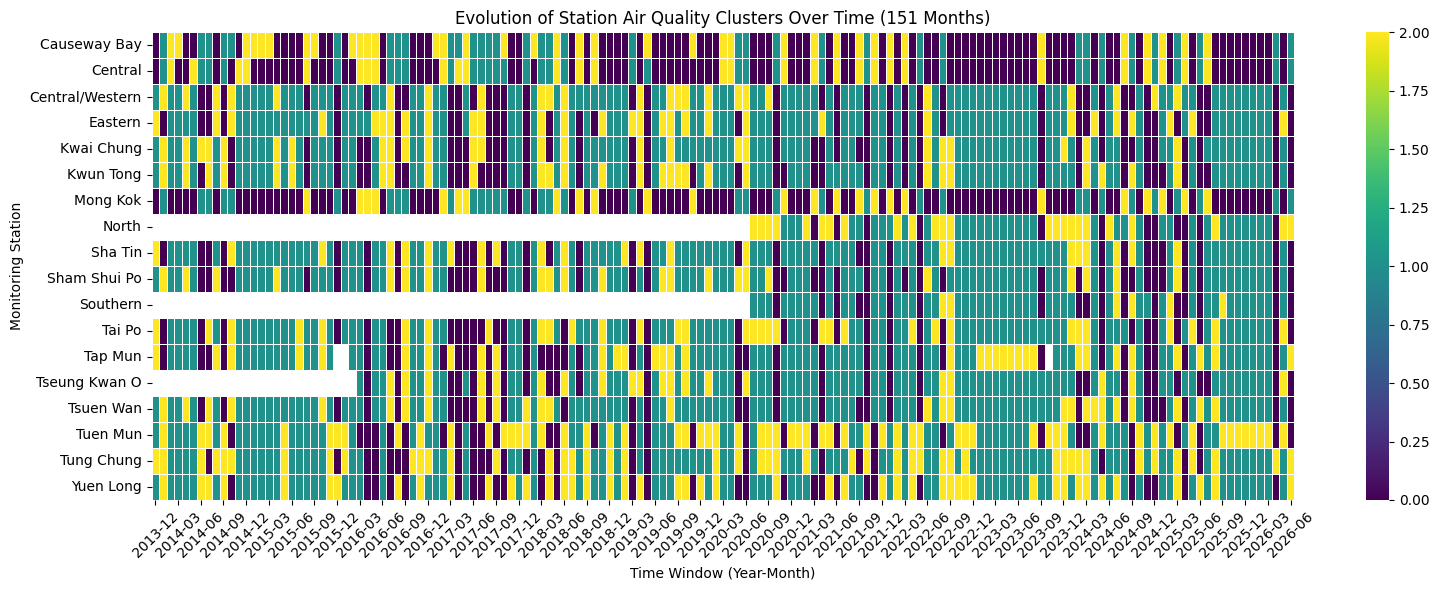

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table: Rows = Stations, Columns = Time (Months), Values = Cluster ID
pivot_clusters = master_cluster_df.reset_index().pivot(
    index='station', 
    columns='year_month', 
    values='cluster'
)

plt.figure(figsize=(16, 6))
sns.heatmap(pivot_clusters, cmap='viridis', cbar=True, linewidths=0.5)
plt.title("Evolution of Station Air Quality Clusters Over Time (151 Months)")
plt.xlabel("Time Window (Year-Month)")
plt.ylabel("Monitoring Station")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [110]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Ensure datetime is parsed and year_month is created
df_feat['datetime'] = pd.to_datetime(df_feat['datetime'])
df_feat['year_month'] = df_feat['datetime'].dt.to_period('M')
periods = df_feat['year_month'].unique()

# 2. Define the clustering function (same as before)
def compute_window_clusters(period, data):
    window_df = data[data['year_month'] == period]
    if window_df.empty:
        return period, None
    
    station_agg = window_df.groupby('station').agg(
        mean_aqhi=('aqhi', 'mean'),
        high_risk_ratio=('is_high', 'mean'),
        is_roadside=('is_roadside', 'max')
    ).dropna()
    
    if len(station_agg) < 3:
        return period, None
        
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(station_agg[['mean_aqhi', 'high_risk_ratio', 'is_roadside']])
    
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    station_agg['cluster'] = kmeans.fit_predict(X_scaled)
    
    return period, station_agg

# 3. Benchmark across different worker configurations (1, 2, 4, 8 workers)
worker_configs = [1, 2, 4, 8]
runtimes = []

for w in worker_configs:
    print(f"Benchmarking sliding-window clustering with n_jobs={w}...")
    start = time.perf_counter()
    
    # Run clustering (n_jobs=1 is sequential, others are parallel)
    results = Parallel(n_jobs=w)(
        delayed(compute_window_clusters)(p, df_feat) for p in periods
    )
    
    elapsed = time.perf_counter() - start
    runtimes.append(elapsed)
    print(f"-> Completed in {elapsed:.3f}s")


Benchmarking sliding-window clustering with n_jobs=1...
-> Completed in 2.362s
Benchmarking sliding-window clustering with n_jobs=2...
-> Completed in 28.761s
Benchmarking sliding-window clustering with n_jobs=4...
-> Completed in 28.054s
Benchmarking sliding-window clustering with n_jobs=8...
-> Completed in 28.055s



--- Sliding-Window Clustering Performance Table ---


,Workers,Runtime (s),Speedup,Efficiency
0,1,2.362384,1.000000,1.000000
1,2,28.761366,0.082137,0.041069
2,4,28.053620,0.084210,0.021052
3,8,28.054795,0.084206,0.010526


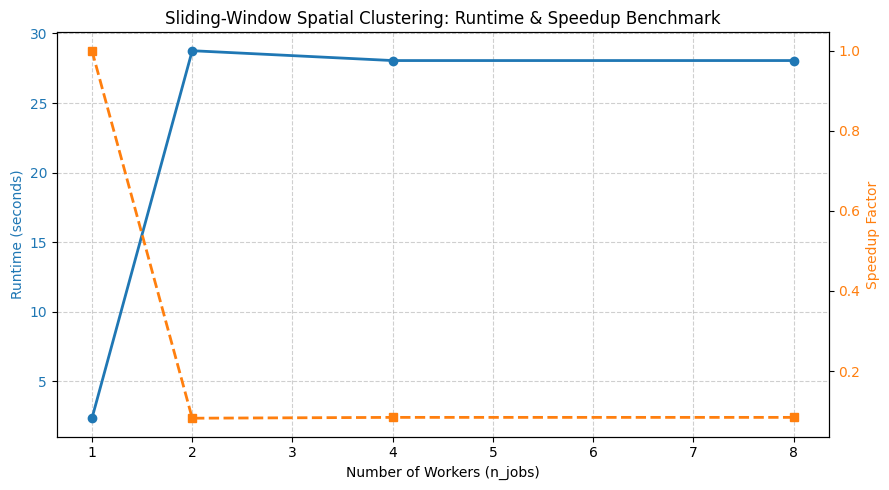

In [111]:
# 4. Build the Runtime Comparison Table
runtime_table = pd.DataFrame({
    "Workers": worker_configs,
    "Runtime (s)": runtimes
})

# Sequential time is when Workers = 1
seq_time = runtime_table.loc[runtime_table["Workers"] == 1, "Runtime (s)"].values[0]

runtime_table["Speedup"] = seq_time / runtime_table["Runtime (s)"]
runtime_table["Efficiency"] = runtime_table["Speedup"] / runtime_table["Workers"]

print("\n--- Sliding-Window Clustering Performance Table ---")
display(runtime_table)

# 5. Visualize Runtime and Speedup
fig, ax1 = plt.subplots(figsize=(9, 5))

# Plot Runtime curve
ax1.set_xlabel("Number of Workers (n_jobs)")
ax1.set_ylabel("Runtime (seconds)", color="tab:blue")
line1 = ax1.plot(runtime_table["Workers"], runtime_table["Runtime (s)"], marker="o", color="tab:blue", linewidth=2, label="Runtime (s)")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(True, linestyle="--", alpha=0.6)

# Create twin axis for Speedup curve
ax2 = ax1.twinx()
ax2.set_ylabel("Speedup Factor", color="tab:orange")
line2 = ax2.plot(runtime_table["Workers"], runtime_table["Speedup"], marker="s", color="tab:orange", linewidth=2, linestyle="--", label="Speedup")
ax2.tick_params(axis="y", labelcolor="tab:orange")

plt.title("Sliding-Window Spatial Clustering: Runtime & Speedup Benchmark")
fig.tight_layout()
plt.show()

In [112]:
import multiprocessing
import os

print(f"CPU Cores (Logical/Threads): {multiprocessing.cpu_count()}")
print(f"CPU Cores (Physical): {os.cpu_count()}")

CPU Cores (Logical/Threads): 10
CPU Cores (Physical): 10


## Stationwise parallel.

Benchmarking station bootstrap with n_jobs=1...
-> Completed in 23.081s
Benchmarking station bootstrap with n_jobs=2...
-> Completed in 12.564s
Benchmarking station bootstrap with n_jobs=4...
-> Completed in 6.167s
Benchmarking station bootstrap with n_jobs=8...
-> Completed in 5.284s

--- 1-2-4-8 Worker Benchmark Results ---


,Workers,Runtime (s),Speedup
0,1,23.080530,1.000000
1,2,12.563508,1.837109
2,4,6.167359,3.742369
3,8,5.284308,4.367749


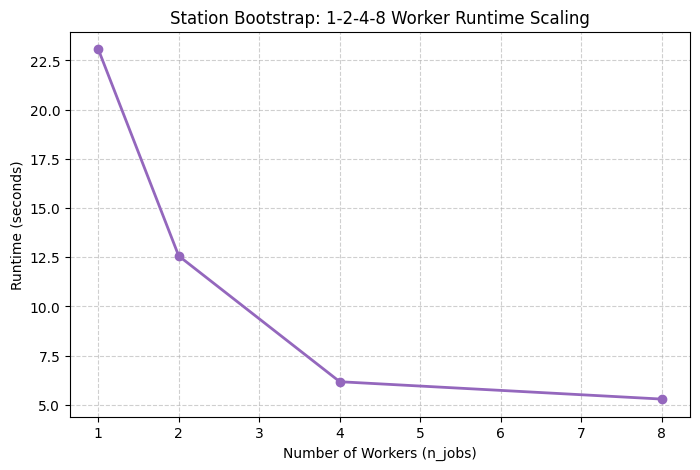

In [120]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# 1. Prepare data
base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"
df_long = pd.read_parquet(f"{base}/aqhi_clean_long.parquet")
df_clean = df_long.dropna(subset=['aqhi', 'station']).copy()
stations = df_clean['station'].unique()

def bootstrap_station(station_name, data, n_boot=1000):
    st_vals = data[data['station'] == station_name]['aqhi'].values
    if len(st_vals) == 0:
        return station_name, np.nan
    rng = np.random.default_rng(42)
    boot_means = [
        rng.choice(st_vals, size=len(st_vals), replace=True).mean()
        for _ in range(n_boot)
    ]
    return station_name, np.mean(boot_means)

# 2. Benchmark 1, 2, 4, 8 Workers
worker_configs = [1, 2, 4, 8]
runtimes = []

for w in worker_configs:
    print(f"Benchmarking station bootstrap with n_jobs={w}...")
    start = time.perf_counter()
    
    _ = Parallel(n_jobs=w)(
        delayed(bootstrap_station)(st, df_clean) for st in stations
    )
    
    elapsed = time.perf_counter() - start
    runtimes.append(elapsed)
    print(f"-> Completed in {elapsed:.3f}s")

# 3. Build Runtime Table
benchmark_df = pd.DataFrame({
    "Workers": worker_configs,
    "Runtime (s)": runtimes
})
seq_time = benchmark_df.loc[benchmark_df["Workers"] == 1, "Runtime (s)"].values[0]
benchmark_df["Speedup"] = seq_time / benchmark_df["Runtime (s)"]

print("\n--- 1-2-4-8 Worker Benchmark Results ---")
display(benchmark_df)

# 4. Plot the 1-2-4-8 Scaling Curve
plt.figure(figsize=(8, 5))
plt.plot(benchmark_df["Workers"], benchmark_df["Runtime (s)"], marker="o", linewidth=2, color="tab:purple")
plt.title("Station Bootstrap: 1-2-4-8 Worker Runtime Scaling")
plt.xlabel("Number of Workers (n_jobs)")
plt.ylabel("Runtime (seconds)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


--- 1-2-4-8 Worker Benchmark Results ---


,Workers,Runtime (s),Speedup
0,1,23.080530,1.000000
1,2,12.563508,1.837109
2,4,6.167359,3.742369
3,8,5.284308,4.367749


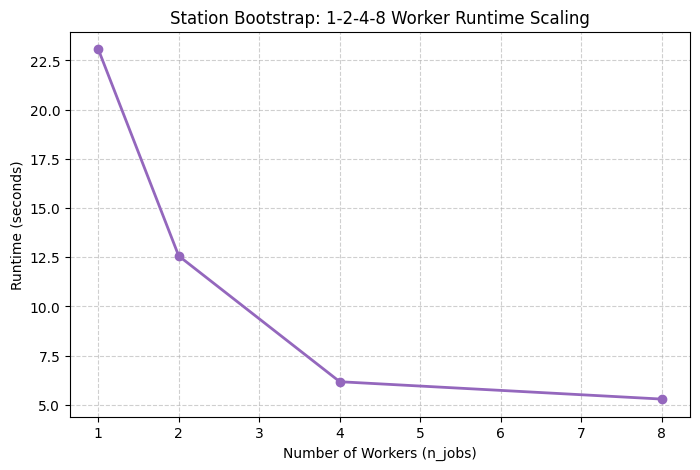

In [121]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# 1. Ensure clean long dataset is loaded and station data is prepared
base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"
df_long = pd.read_parquet(f"{base}/aqhi_clean_long.parquet")

# Filter out missing AQHI values
df_clean = df_long.dropna(subset=['aqhi', 'station']).copy()
stations = df_clean['station'].unique()

print(f"Total stations found for bootstrapping: {len(stations)}")

# 2. Define the single-station bootstrap function
def bootstrap_station(station_name, data, n_boot=1000):
    st_vals = data[data['station'] == station_name]['aqhi'].values
    if len(st_vals) == 0:
        return station_name, np.nan, np.nan, np.nan
    
    rng = np.random.default_rng(42)
    # Generate bootstrap sample means
    boot_means = [
        rng.choice(st_vals, size=len(st_vals), replace=True).mean()
        for _ in range(n_boot)
    ]
    
    mean_val = np.mean(boot_means)
    ci_lower = np.percentile(boot_means, 2.5)
    ci_upper = np.percentile(boot_means, 97.5)
    
    return station_name, mean_val, ci_lower, ci_upper

# 3. Benchmark Sequential vs. Parallel Execution across the 18 stations
print("\nRunning Station-by-Station Bootstrap (Parallel Workers)...")
start = time.perf_counter()

# Using parallel processing across available cores for the 18 stations
results = Parallel(n_jobs=-1)(
    delayed(bootstrap_station)(st, df_clean) for st in stations
)

elapsed_time = time.perf_counter() - start
print(f"-> Completed station-level bootstrap in {elapsed_time:.3f} seconds.")

# 4. Build Summary DataFrame
station_boot_df = pd.DataFrame(results, columns=['Station', 'Mean_AQHI', 'CI_Lower', 'CI_Upper'])
station_boot_df = station_boot_df.sort_values(by='Mean_AQHI', ascending=False).reset_index(drop=True)

print("\n--- Top 5 Stations by Bootstrap AQHI Mean ---")
display(station_boot_df.head(5))

# 5. Visualize Confidence Intervals across all stations
plt.figure(figsize=(10, 6))
plt.errorbar(
    station_boot_df['Mean_AQHI'], 
    station_boot_df['Station'], 
    xerr=[
        station_boot_df['Mean_AQHI'] - station_boot_df['CI_Lower'], 
        station_boot_df['CI_Upper'] - station_boot_df['Mean_AQHI']
    ], 
    fmt='o', color='tab:red', ecolor='gray', elinewidth=1.5, capsize=3
)
plt.title("Station-by-Station AQHI Mean & 95% Bootstrap Confidence Intervals")
plt.xlabel("AQHI Mean Score")
plt.ylabel("Monitoring Station")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

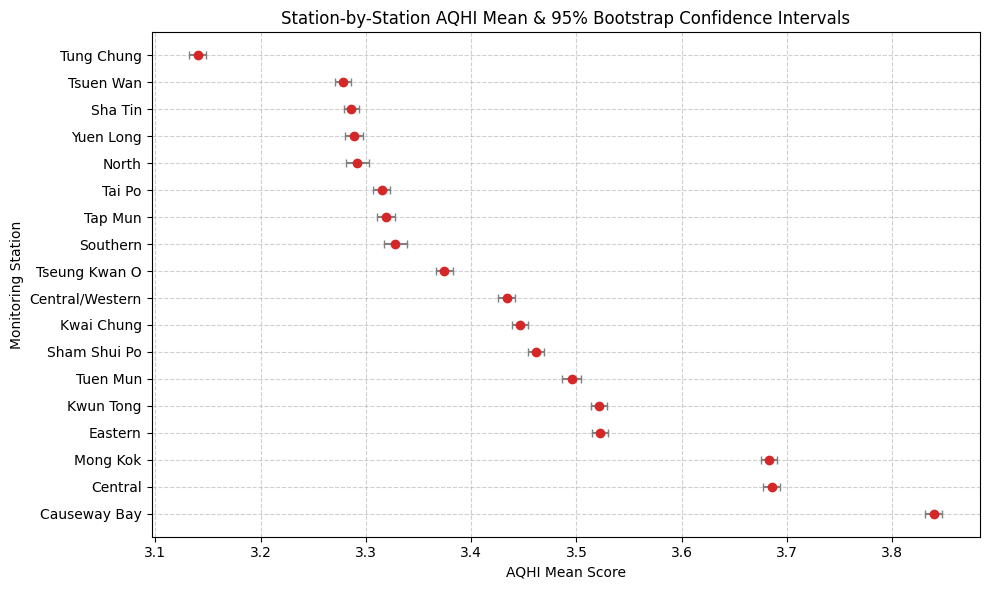

In [122]:
# Lightweight plotting cell using already-computed 'station_boot_df'
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.errorbar(
    station_boot_df['Mean_AQHI'], 
    station_boot_df['Station'], 
    xerr=[
        station_boot_df['Mean_AQHI'] - station_boot_df['CI_Lower'], 
        station_boot_df['CI_Upper'] - station_boot_df['Mean_AQHI']
    ], 
    fmt='o', color='tab:red', ecolor='gray', elinewidth=1.5, capsize=3
)
plt.title("Station-by-Station AQHI Mean & 95% Bootstrap Confidence Intervals")
plt.xlabel("AQHI Mean Score")
plt.ylabel("Monitoring Station")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Total rows for permutation simulation: 1820866

Running Permutation Simulation with n_jobs=1...
-> Completed in 7.084s

Running Permutation Simulation with n_jobs=2...
-> Completed in 4.424s

Running Permutation Simulation with n_jobs=4...
-> Completed in 3.463s

Running Permutation Simulation with n_jobs=8...
-> Completed in 2.854s

--- Permutation Simulation Benchmark Results ---


,Workers,Runtime (s),Speedup
0,1,7.083722,1.000000
1,2,4.424184,1.601137
2,4,3.462875,2.045619
3,8,2.854024,2.482012


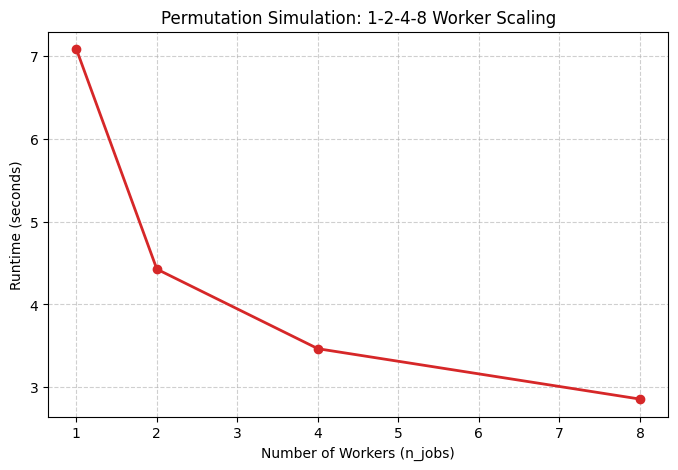

In [140]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

# 1. Load your clean long dataset
base = "/Users/kesiyun/Desktop/5488 Big Data/5488Project Big Data/part1_hcs/part1_deliverables"
df_long = pd.read_parquet(f"{base}/aqhi_clean_long.parquet")

df_clean = df_long.dropna(subset=['aqhi']).copy()
aqhi_vals = df_clean['aqhi'].values
print(f"Total rows for permutation simulation: {len(aqhi_vals)}")

# 2. Define the permutation function
def run_single_permutation(seed):
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation(aqhi_vals)
    half = len(shuffled) // 2
    stat = np.mean(shuffled[:half]) - np.mean(shuffled[half:])
    return stat

# 3. Benchmark across worker configs without progress bar
worker_configs = [1, 2, 4, 8]
total_permutations = 200 
runtimes = []

for w in worker_configs:
    print(f"\nRunning Permutation Simulation with n_jobs={w}...")
    start = time.perf_counter()
    
    results = Parallel(n_jobs=w, batch_size=1)(
        delayed(run_single_permutation)(seed=i) for i in range(total_permutations)
    )
        
    elapsed = time.perf_counter() - start
    runtimes.append(elapsed)
    print(f"-> Completed in {elapsed:.3f}s")

# 4. Build Runtime Table & Speedup
benchmark_df = pd.DataFrame({
    "Workers": worker_configs,
    "Runtime (s)": runtimes
})
seq_time = benchmark_df.loc[benchmark_df["Workers"] == 1, "Runtime (s)"].values[0]
benchmark_df["Speedup"] = seq_time / benchmark_df["Runtime (s)"]

print("\n--- Permutation Simulation Benchmark Results ---")
display(benchmark_df)

# 5. Plot the Scaling Curve
plt.figure(figsize=(8, 5))
plt.plot(benchmark_df["Workers"], benchmark_df["Runtime (s)"], marker="o", linewidth=2, color="tab:red")
plt.title("Permutation Simulation: 1-2-4-8 Worker Scaling")
plt.xlabel("Number of Workers (n_jobs)")
plt.ylabel("Runtime (seconds)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


Observed Statistic: 0.2106
Empirical P-value: 0.0000


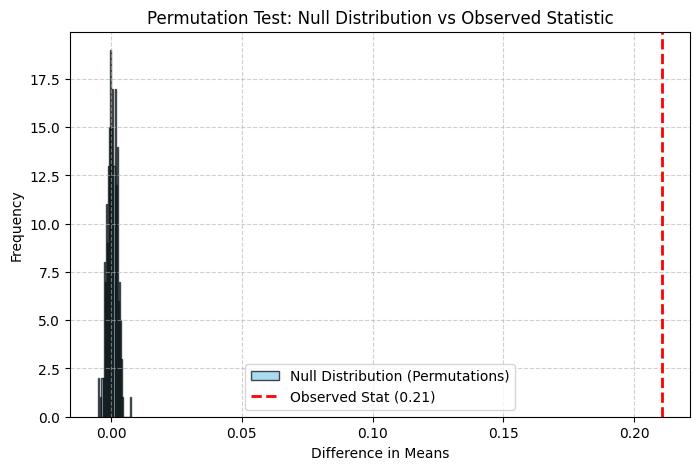

In [142]:
# ... [keep everything above step 5 the same] ...

# 5. Calculate the Actual Observed Statistic (from your real unshuffled data)
# For example, splitting your actual data right down the middle as a baseline comparison:
real_half = len(aqhi_vals) // 2
observed_stat = np.mean(aqhi_vals[:real_half]) - np.mean(aqhi_vals[real_half:])

# Use the results from your last parallel run (e.g., n_jobs=8)
permuted_stats = np.array(results)

# Calculate Empirical P-value
# (How many random shuffles produced a difference as extreme as your real data?)
p_value = np.sum(np.abs(permuted_stats) >= np.abs(observed_stat)) / len(permuted_stats)
print(f"\nObserved Statistic: {observed_stat:.4f}")
print(f"Empirical P-value: {p_value:.4f}")

# 6. Plot the Null Distribution Histogram
plt.figure(figsize=(8, 5))
plt.hist(permuted_stats, bins=30, color='skyblue', edgecolor='black', alpha=0.7, label='Null Distribution (Permutations)')
plt.axvline(observed_stat, color='red', linestyle='--', linewidth=2, label=f'Observed Stat ({observed_stat:.2f})')
plt.title("Permutation Test: Null Distribution vs Observed Statistic")
plt.xlabel("Difference in Means")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()